In [176]:
import os 
from dotenv import load_dotenv
load_dotenv()

from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph,START,END
from langchain_community.tools import DuckDuckGoSearchRun
from langchain.tools import tool
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage,ToolMessage


In [177]:
if os.environ.get("OPENAI_API_KEY"):
    print("API Key exists!")
else:
    raise ValueError("API Key not present!")

API Key exists!


In [178]:
llm = init_chat_model("gpt-5-nano",temperature=0)


In [179]:
@tool
def search_duckduckgo(query:str)-> str:
    """Searches the web using DuckDuckGo and returns the results."""
    search = DuckDuckGoSearchRun()
    return search.run(query)

In [180]:
from langchain_community.tools import ArxivQueryRun
from langchain_community.utilities import ArxivAPIWrapper

@tool
def arxiv_query(query: str):
    """Search for papers on arxiv.org."""
    
    arxiv_query = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())
    return arxiv_query.invoke(query)




In [181]:
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

@tool
def wiki_tool(query:str):
    """
    A tool that queries Wikipedia for information."""

    wikipedia_query = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper())
    return wikipedia_query.invoke(query)



In [182]:
#Custom Tool Example
from langchain.tools import tool

@tool
def personal_info(name:str):

    """Retrieve personal information about a person by their name."""

    info = {
        "Alice": "Alice is a software engineer with 5 years of experience in web development.",
        "Bob": "Bob is a data scientist who specializes in machine learning and AI.",
        "Charlie": "Charlie is a product manager with a background in UX design and project management."
    }
    return info.get(name, "No information available for this person.")

In [183]:
tools = [search_duckduckgo, arxiv_query, wiki_tool, personal_info]

llm_with_tools = llm.bind_tools(tools)

In [184]:
from typing import TypedDict,List

class graph_schema(TypedDict):
    messages: List
   

In [185]:
def llm_node(state:graph_schema)->graph_schema:
    messages = state['messages']
    prompt = ChatPromptTemplate.from_messages([
        ("system","You are a helpfull assistant to answer the questions"),
        ("user","{input}")
    ])
    chain = prompt | llm_with_tools

    response = chain.invoke({"input":messages})

    state['messages'] = messages + [response]

    return state




In [186]:
# from langgraph.prebuilt import ToolNode


def tool_node(state:graph_schema)-> graph_schema:
    messages = state['messages']

    tools_by_name = {tool.name:tool for tool in tools }
    tool_results = []

    for tool_call in messages[-1].tool_calls:
        tool= tools_by_name[tool_call["name"]]
        observation = tool.invoke(tool_call["args"])
        tool_results.append(ToolMessage(content=observation,tool_call_id = tool_call['id']))
    state['messages'] = messages + tool_results
    return state

In [187]:
#Create Condotional Edge

def if_tool_call(state:graph_schema)->str:

    last_message = state['messages'][-1]

    if last_message.tool_calls:
        return "tool_node"
    else:
        return "end"


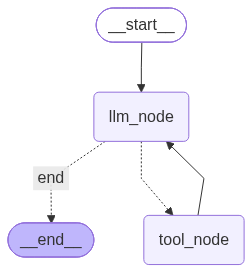

In [188]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(graph_schema)

graph.add_node("llm_node",llm_node)

graph.add_node("tool_node",tool_node)

graph.add_edge(START,"llm_node")
graph.add_conditional_edges("llm_node",if_tool_call,{"tool_node": "tool_node", "end": END})
graph.add_edge("tool_node","llm_node")
graph.add_edge("llm_node",END)

react_graph = graph.compile()

from IPython.display import Image,display
Image(react_graph.get_graph().draw_mermaid_png())

In [189]:
react_graph.invoke({"messages":[HumanMessage(content="what is the latest news on ai?")]})


{'messages': [HumanMessage(content='what is the latest news on ai?', additional_kwargs={}, response_metadata={}),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 742, 'prompt_tokens': 237, 'total_tokens': 979, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 640, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-nano-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EYF4RrowzFrM9kuGZH0S4HkFzq4Ml', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a13160-ce17-7ef0-abce-2a46703432b7-0', tool_calls=[{'name': 'search_duckduckgo', 'args': {'query': 'latest AI news today'}, 'id': 'call_UgLrEjrasAmENVElroClgFcJ', 'type': 'tool_call'}, {'